# ESPRESSO: does the choice of reanalysis matter? (HAT-P-26)

gtellcorr builds the atmosphere of every exposure from meteorological data, and it can
take the lower atmosphere from several sources. The fit scales the column of water but
not the shape of its profile, which comes from the source. This notebook asks how much
the choice of source changes the result. We correct the same ESPRESSO exposure of the
K dwarf HAT-P-26 (VLT, 2022 July 3) three times, with the lower atmosphere from ERA5,
MERRA-2 and the GDAS profiles that ESO provides, everything else being identical, and
compare the three results.

We proceed in four steps:

1. **The exposure.** We read the spectrum.
2. **Three profiles.** We build the three atmospheres and compare their water.
3. **The fits.** We synthesise the stellar template once and run the three fits.
4. **The three results.** We compare the fitted parameters and the corrected spectra.

**What you need.** gtellcorr with its LBLRTM bundle and reference files, pySME and a
VALD line list for the template (the `stellar_linelist` setting), and the ESPRESSO file
`r.ESPRE.2022-07-03T00:40:54.453_S2D_A.fits` (public, ESO archive) in
`$GTELLCORR_PAPER_DATA/hatp26_espresso/`. ERA5 needs a Copernicus account and MERRA-2 a
NASA Earthdata token, both given in the credentials file (`WEATHER_KEYS`); the ESO GDAS
profiles need no account. Each source needs its own optical depths for every ESPRESSO
order, so the first run takes about an hour per source; later runs reuse them.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.integrate import trapezoid

import gtellcorr as gtc
from gtellcorr.data.atmosphere import AtmosphereConfig, full_profile_for_exposure
from gtellcorr.plotting import plot_order_fit, plot_profiles

data = Path(os.environ.get("GTELLCORR_PAPER_DATA", "paper_data"))
output = Path(os.environ.get("GTELLCORR_PAPER_OUT", "paper_runs")) / "espresso_hatp26_meteo"
settings = gtc.Settings.load()
plt.rcParams["figure.dpi"] = 72  # keeps the figures in the notebook small
print("gtellcorr", gtc.__version__)

gtellcorr 0.10.0


## 1. The exposure

We read the spectrum with the ESPRESSO instrument description, as in the previous
notebook. The weather measured at the telescope shows a very dry night: a relative
humidity of a few percent at the ground.

In [2]:
star = gtc.Star(name="HAT-P-26", teff=5079.0, logg=4.56, feh=-0.04, vsini_kms=1.0, vsys_kms=14.72)
obs = gtc.Observation.from_directory(
    data / "hatp26_espresso", instrument="VLT/ESPRESSO", target=star
)
exposure = obs.exposures[0]
print(
    f"{exposure.name}\nmid-exposure {exposure.time_utc:%Y-%m-%d %H:%M:%S} UTC, "
    f"airmass {exposure.airmass:.2f}, R = {exposure.resolution:.0f}"
)
print("on-site weather:", exposure.weather)

r.ESPRE.2022-07-03T00:40:54.453_S2D_A.fits
mid-exposure 2022-07-03 00:46:44 UTC, airmass 1.15, R = 140000
on-site weather: OnSiteWeather(T_K=286.53999999999996, RH_pct=4.5, P_hpa=743.2, dewpoint_K=None, time=None)


## 2. Three profiles

The source of the lower atmosphere is set by `atmosphere.lower_backend`. The three we
compare differ in how often and on how fine a grid they give the atmosphere:

- `"era5_cdsapi"`: ERA5, the reanalysis of ECMWF (the default), hourly on a 0.25° grid;
- `"merra2_gesdisc"`: MERRA-2, the reanalysis of NASA, every three hours on a
  0.5° × 0.625° grid;
- `"eso_gdas"`: the GDAS profiles of NOAA that ESO distributes for its sites, every
  three hours on a 0.5° grid.

gtellcorr takes the time step nearest to the middle of the exposure. Above the
reanalysis it uses the NRLMSIS-00 model, and the molecules that a reanalysis does not
give come from a reference atmosphere; both are the same for the three sources.
`full_profile_for_exposure` takes the source in its `config`:

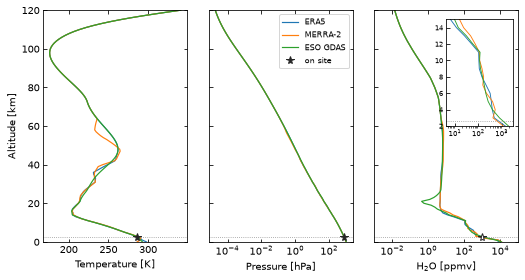

In [3]:
sources = {"ERA5": "era5_cdsapi", "MERRA-2": "merra2_gesdisc", "ESO GDAS": "eso_gdas"}
profiles = {
    label: full_profile_for_exposure(
        exposure,
        obs.instrument,
        settings=settings,
        config=AtmosphereConfig(lower_backend=backend),
    )
    for label, backend in sources.items()
}
site_km = exposure.site.alt_m / 1000
fig, axes = plot_profiles(
    profiles, site_alt_km=site_km, onsite=exposure.weather, inset_z_km=(2.0, 15.0)
)

What matters most for the telluric lines is the precipitable water vapour (PWV) above
the observatory: the column of water the light crosses at the zenith, expressed as the
depth of the water it would make if condensed. We integrate it from each profile:

In [4]:
def pwv_mm(profile, above_km):
    # water vapour density from the mixing ratio and the ideal gas law, integrated in z
    z = np.asarray(profile["z_km"]) * 1e3
    n = np.asarray(profile["P_hPa"]) * 100 / (1.380649e-23 * np.asarray(profile["T_K"]))
    rho = n * np.asarray(profile["H2O_ppmv"]) * 1e-6 * 18.015e-3 / 6.02214076e23  # kg/m3
    fine = np.linspace(above_km * 1e3, z[-1], 20000)
    return float(trapezoid(np.exp(np.interp(fine, z, np.log(rho))), fine))  # kg/m2 = mm


pwv = {label: pwv_mm(profile, site_km) for label, profile in profiles.items()}
for label, value in pwv.items():
    print(f"{label:9s} PWV above the site: {value:.3f} mm")

ERA5      PWV above the site: 0.940 mm
MERRA-2   PWV above the site: 0.962 mm
ESO GDAS  PWV above the site: 0.997 mm


The three sources agree that the night was dry, about 1 mm of water, but differ by up
to 6 %, and their profiles also differ in shape. If the fit only had to find the
column, the shape would not matter; the question is whether it does.

## 3. The fits

### The stellar template

The star is modelled with a pySME template, synthesised once and used by all three
fits, so that the stellar model cannot differ between them. `Pipeline.prepare` runs the
preparation steps of a fit (template, RV, masks) without fitting, and we take the
template it made:

In [5]:
base = {"stellar": "template", "continuum": {"order": 2}}
prep = gtc.Pipeline(
    obs,
    gtc.FitConfig.from_dict(base),
    output_dir=output / "template",
    settings=settings,
    plot=False,
)
prep.prepare()
(template,) = (prep.layout.root / "template_stellar_spectrum" / "data").glob("*_rest.dat")
print(template.name)

HAT-P-26_pySME-VALD_Teff5079_logg4.56_MH-0.0_vsini1.0kms_R140000_377-791nm_rest.dat


### The settings

The three fits share every setting except the source, written out here in full:

- `stellar = "template"` and `stellar_model.template_file`: the template above;
- `continuum.order = 2`: a continuum of degree 2 per order, as for GJ 436;
- `lsf.fit_resolution = true`: the resolving power is fitted in every fit order, within
  8 % of 140 000 (the default bounds);
- `relcol_mode = "joint_orders"`: one H{sub}`2`O and one O{sub}`2` column shared by the
  24 anchor orders;
- `wavelength.fit = false`: no wavelength correction (the default);
- `atmosphere.lower_backend`: ERA5, MERRA-2 or ESO GDAS, the one difference.

In [6]:
results = {}
for label, backend in sources.items():
    config = gtc.FitConfig.from_dict(
        {
            "stellar": "template",
            "stellar_model": {"template_file": str(template)},
            "continuum": {"order": 2},
            "lsf": {"fit_resolution": True},
            "relcol_mode": "joint_orders",
            "wavelength": {"fit": False},
            "atmosphere": {"lower_backend": backend},
        }
    )
    results[label] = gtc.run(
        obs, config, output_dir=output / backend, settings=settings, plot=False
    )

## 4. The three results

### Fitted parameters

The fitted relative column $s_{\rm H_2O}$ scales the profile of each source, so the
water that the spectrum measures is $s_{\rm H_2O}$ times the PWV of that profile:

In [7]:
rows = []
for label, res in results.items():
    table = res.exposures[0].order_table
    fitted = table[table["used_in_fit"]]
    relcol = {}
    for _, row in fitted.iterrows():
        relcol |= json.loads(row["relcol"])
    rows.append(
        {
            "source": label,
            "PWV profile [mm]": pwv[label],
            "s_H2O": relcol["h2o"],
            "fitted PWV [mm]": relcol["h2o"] * pwv[label],
            "s_O2": relcol["o2"],
            "median R": float(np.median(fitted["resolution"])),
            "joint reduced chi2": float(fitted["chi2_reduced_joint"].iloc[0]),
        }
    )
pd.DataFrame(rows).set_index("source").round(4)

,PWV profile [mm],s_H2O,fitted PWV [mm],s_O2,median R,joint reduced chi2
source,,,,,,
ERA5,0.9401,1.0441,0.9816,1.0199,140488.5815,4.9159
MERRA-2,0.9625,1.0193,0.9811,1.0218,140093.9983,4.9129
ESO GDAS,0.9972,0.9915,0.9887,1.0190,141544.6018,4.9155


The profiles hold 0.940, 0.962 and 0.997 mm of water, and the fit scales each by a
different factor, 1.044, 1.019 and 0.992. The water in the spectrum, their product, comes
out the same: 0.982, 0.981 and 0.989 mm, within 0.8 %. The relative columns of different
sources are therefore not comparable with each other, while the fitted PWV is. The other
parameters hardly change: O{sub}`2` within 0.3 %, the median $R$ within 1 % and the
reduced $\chi^2$ within 0.1 %.

### The corrected spectra

How different are the corrected spectra? We compare them pixel by pixel on the water
orders, as a fraction of the noise of the corrected flux (`ERR_CORRECTED`), with ERA5 as
the reference. Pixels left out of either fit are not compared.

In [8]:
reference = results["ERA5"].exposures[0]
water = [o for o in reference.orders if o in set(obs.instrument.anchor_orders["h2o"])]
rows_index = [int(np.flatnonzero(reference.orders == o)[0]) for o in water]
for label in ("MERRA-2", "ESO GDAS"):
    other = results[label].exposures[0]
    diff, noise = [], []
    for i in rows_index:
        keep = ~reference.exclusion[i] & ~other.exclusion[i]
        diff.append((other.flux_corrected[i] - reference.flux_corrected[i])[keep])
        noise.append(reference.image("ERR_CORRECTED")[i][keep])
    ratio = np.abs(np.concatenate(diff)) / np.concatenate(noise)
    print(
        f"{label} - ERA5: median |difference| {np.nanmedian(ratio):.3f} x noise, "
        f"99th percentile {np.nanpercentile(ratio, 99):.3f} x noise"
    )

MERRA-2 - ERA5: median |difference| 0.000 x noise, 99th percentile 0.034 x noise
ESO GDAS - ERA5: median |difference| 0.001 x noise, 99th percentile 0.045 x noise


Let's look at one water order, 154, which holds the strongest water lines of this dry
night: its fit with ERA5, and the differences of the corrected spectra against the
noise:

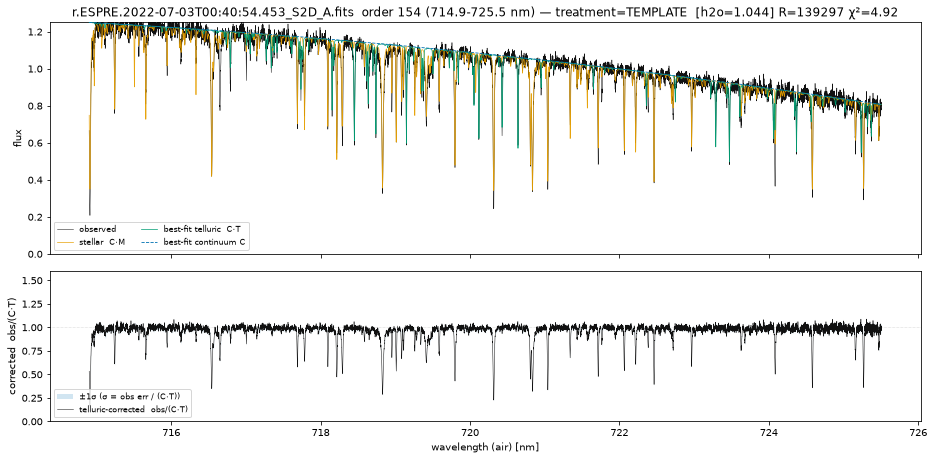

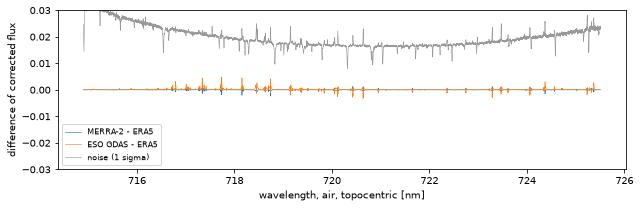

In [9]:
order = 154
fig, axes = plot_order_fit(str(reference.path), order=order, out=False)

i = int(np.flatnonzero(reference.orders == order)[0])
fig, ax = plt.subplots(figsize=(9, 3))
for label in ("MERRA-2", "ESO GDAS"):
    other = results[label].exposures[0]
    ax.plot(
        reference.wave[i],
        other.flux_corrected[i] - reference.flux_corrected[i],
        lw=0.6,
        label=f"{label} - ERA5",
    )
ax.plot(
    reference.wave[i],
    reference.image("ERR_CORRECTED")[i],
    color="0.6",
    lw=0.6,
    label="noise (1 sigma)",
)
ax.set_ylim(-0.03, 0.03)
ax.set_xlabel("wavelength, air, topocentric [nm]")
ax.set_ylabel("difference of corrected flux")
ax.legend(fontsize=8, loc="lower left")
fig.tight_layout()

The corrected spectra differ only at the water lines, by a few thousandths of the flux,
against a noise of about 2 %. Over all water orders the median difference is a thousandth
of the noise, and 99 % of the pixels differ by less than 5 % of it. For this exposure the
choice of source therefore does not matter: the fit absorbs the difference in the water
column, and the differences in the shape of the profiles change the telluric lines far
less than the noise. This is one dry night; on a wetter night the profiles, and their
effect on the correction, may differ more.